# Extração do GDELT - Eleições no Brasil, 2026

**Pergunta do projeto:** como fontes nacionais e internacionais enquadram as eleições no Brasil de 2026 em tom, temas, emoções e atores?

#### Configuração

In [1]:
import json, datetime as dt
from pathlib import Path
import pandas as pd
from google.cloud import bigquery

In [2]:
# --- Projeto e destino ---
PROJECT = "gdelt-dataviz-pgatti"
DATASET = "gdelt_eleicoes"
TABELA  = "gkg_eleicoes2026_raw"

# --- Evento e janela ---
EVENTO = "Eleicoes_BR_2026"
INICIO, FIM = "2026-10-01", "2026-10-30"

# --- Controles de custo e execução ---
MAX_GB = 130
RODAR_EXTRACAO = True       # roda a query só se ainda não existir raw local
FORCAR_REEXTRACAO = False   # True = refaz a query mesmo com raw local (cobra de novo)

RAW = Path("../data/raw")
RAW.mkdir(parents=True, exist_ok=True)

#### Query e parâmetros

O filtro é **propositalmente amplo**: (tema de eleição **E** localização no Brasil) **OU** URL. A relevância é refinada depois, no Python, com funil de contagens.

- Diferente das enchentes, um evento nacional não tem um conjunto pequeno de localidades: filtrar só por "Brasil" em `V2Locations` traria praticamente todo o noticiário brasileiro. Por isso a localização (`#BR#`, código FIPS do país) é combinada com os temas de eleição do GKG (`ELECTION`, que também cobre variantes como `ELECTION_FRAUD` e `WB_*_ELECTIONS`).
- O ramo de URL captura matérias que o GDELT não marcou com o tema, com termos em português, inglês e espanhol para não enviesar a favor de fontes em português.

Atenção: filtrar linhas **não reduz o custo**. A cobrança depende das colunas lidas e dos dias (partições) varridos.

In [3]:
SQL = """
SELECT
  GKGRECORDID,
  PARSE_TIMESTAMP('%Y%m%d%H%M%S', CAST(DATE AS STRING)) AS DataHora,
  SourceCommonName AS Veiculo,
  DocumentIdentifier AS URL,
  V2Tone, V2Themes, V2Locations, GCAM,
  V2Persons, V2Organizations, TranslationInfo
FROM `gdelt-bq.gdeltv2.gkg_partitioned`
WHERE _PARTITIONDATE BETWEEN @d_ini AND @d_fim
  AND DATE BETWEEN @ts_ini AND @ts_fim
  AND ((REGEXP_CONTAINS(V2Themes, @re_tema) AND REGEXP_CONTAINS(V2Locations, @re_local))
       OR REGEXP_CONTAINS(LOWER(DocumentIdentifier), @re_url))
"""

RE_TEMA  = r"ELECTION"
RE_LOCAL = r"#BR#"   # código de país (FIPS) dentro de cada entrada de V2Locations

# Inclui termos em inglês e espanhol para não enviesar a favor de fontes em português
RE_URL = (r"eleic|elei%c3%a7|segundo-turno|primeiro-turno"
          r"|brazil.{0,40}(?:election|vote|voting|ballot|runoff|poll)"
          r"|(?:election|vote|voting|ballot|runoff|poll).{0,40}brazil"
          r"|brasil.{0,40}(?:elecci|balotaje|segunda-vuelta|votaci)"
          r"|(?:elecci|balotaje|segunda-vuelta|votaci).{0,40}brasil")

def make_config(dry_run=False, destination=None, max_gb=None):
    d_ini, d_fim = dt.date.fromisoformat(INICIO), dt.date.fromisoformat(FIM)
    params = [
        bigquery.ScalarQueryParameter("d_ini", "DATE", d_ini),
        bigquery.ScalarQueryParameter("d_fim", "DATE", d_fim),
        bigquery.ScalarQueryParameter("ts_ini", "INT64", int(f"{d_ini:%Y%m%d}000000")),
        bigquery.ScalarQueryParameter("ts_fim", "INT64", int(f"{d_fim:%Y%m%d}235959")),
        bigquery.ScalarQueryParameter("re_tema", "STRING", RE_TEMA),
        bigquery.ScalarQueryParameter("re_local", "STRING", RE_LOCAL),
        bigquery.ScalarQueryParameter("re_url", "STRING", RE_URL),
    ]
    kw = dict(query_parameters=params, dry_run=dry_run, use_query_cache=not dry_run)
    if destination:
        kw.update(destination=destination, write_disposition="WRITE_TRUNCATE")
    if max_gb:
        kw.update(maximum_bytes_billed=int(max_gb * 10**9))
    return bigquery.QueryJobConfig(**kw)

client = bigquery.Client(project=PROJECT)
# O GDELT público fica na região US; o dataset de destino precisa estar na mesma região
ds = bigquery.Dataset(f"{PROJECT}.{DATASET}")
ds.location = "US"
client.create_dataset(ds, exists_ok=True)
print("Cliente BigQuery OK | projeto:", client.project)

Cliente BigQuery OK | projeto: gdelt-dataviz-pgatti


#### Dry run

In [4]:
job = client.query(SQL, job_config=make_config(dry_run=True))
gb = job.total_bytes_processed / 1e9
print(f"Janela {INICIO} a {FIM}: {gb:.1f} GB estimados ({gb/1024:.3f} TiB)")
print("Dentro do teto" if gb <= MAX_GB else f"ACIMA do teto de {MAX_GB} GB: ajuste a janela ou o teto conscientemente")

Janela 2026-10-01 a 2026-10-30: 89.8 GB estimados (0.088 TiB)
Dentro do teto


#### Extração

A query roda **uma única vez** e grava o resultado numa tabela de destino no BigQuery. A leitura para o pandas é feita a partir dessa tabela (`list_rows`, sem custo de query), então uma falha local (ex.: `db-dtypes` ausente) não obriga a pagar a query de novo.
Se já existe um raw local para a mesma janela, a extração é pulada, a menos que `FORCAR_REEXTRACAO=True`.

In [5]:
ref = f"{PROJECT}.{DATASET}.{TABELA}"
existentes = sorted(RAW.glob(f"gkg_{EVENTO}_{INICIO}_{FIM}_*.parquet"))

if not RODAR_EXTRACAO:
    print("RODAR_EXTRACAO=False: extração pulada.")
elif existentes and not FORCAR_REEXTRACAO:
    print(f"Raw já existe ({existentes[-1].name}): extração pulada. Use FORCAR_REEXTRACAO=True para refazer.")
elif gb > MAX_GB:
    raise RuntimeError(f"Dry run ({gb:.1f} GB) acima do teto de {MAX_GB} GB: extração não executada.")
else:
    job_ext = client.query(SQL, job_config=make_config(destination=ref, max_gb=MAX_GB))
    job_ext.result()
    print(f"Query OK | {job_ext.total_bytes_billed/1e9:.1f} GB cobrados | destino: {ref}")

    df = client.list_rows(ref).to_dataframe()
    df.insert(0, "Evento", EVENTO)

    stamp = dt.datetime.now().strftime("%Y%m%d_%H%M")
    base = RAW / f"gkg_{EVENTO}_{INICIO}_{FIM}_{stamp}"
    df.to_parquet(f"{base}.parquet", index=False)
    with open(f"{base}.json", "w", encoding="utf-8") as f:
        json.dump({"executado_em": stamp, "evento": EVENTO, "inicio": INICIO, "fim": FIM,
                   "linhas": len(df), "bytes_cobrados": job_ext.total_bytes_billed,
                   "job_id": job_ext.job_id, "tabela_destino": ref, "sql": SQL,
                   "re_tema": RE_TEMA, "re_local": RE_LOCAL, "re_url": RE_URL},
                  f, ensure_ascii=False, indent=2)
    print(f"Salvo: {base}.parquet ({len(df):,} linhas)")

Query OK | 89.8 GB cobrados | destino: gdelt-dataviz-pgatti.gdelt_eleicoes.gkg_eleicoes2026_raw
Salvo: ../data/raw/gkg_Eleicoes_BR_2026_2026-10-01_2026-10-30_20261103_1816.parquet (95,422 linhas)


#### Exploração inicial

In [6]:
arquivos = sorted(RAW.glob(f"gkg_{EVENTO}_{INICIO}_{FIM}_*.parquet"))
assert arquivos, "Nenhum raw encontrado: rode a extração com RODAR_EXTRACAO=True"
arquivo = arquivos[-1]
print("Lendo:", arquivo.name)
df = pd.read_parquet(arquivo)

print(f"Linhas: {len(df):,} | docs únicos (GKGRECORDID): {df['GKGRECORDID'].nunique():,} | URLs únicas: {df['URL'].nunique():,}")
print(f"Memória: {df.memory_usage(deep=True).sum()/1e6:.0f} MB")

Lendo: gkg_Eleicoes_BR_2026_2026-10-01_2026-10-30_20261103_1816.parquet
Linhas: 95,422 | docs únicos (GKGRECORDID): 95,403 | URLs únicas: 95,422
Memória: 1120 MB


In [7]:
# Completude das colunas principais
cols = ["V2Tone", "V2Themes", "V2Locations", "GCAM", "V2Persons", "V2Organizations", "TranslationInfo", "Veiculo"]
print((df[cols].notna().mean().mul(100).round(1)).to_string())
print(f"\n% traduzidos (TranslationInfo preenchido): {df['TranslationInfo'].notna().mean()*100:.1f}%")

V2Tone             100.0
V2Themes            99.7
V2Locations         95.6
GCAM               100.0
V2Persons           61.9
V2Organizations     80.8
TranslationInfo     87.9
Veiculo            100.0

% traduzidos (TranslationInfo preenchido): 87.9%


In [8]:
# Funil inicial: por qual ramo do filtro cada documento entrou?
por_tema_local = (df["V2Themes"].fillna("").str.contains(RE_TEMA, regex=True)
                  & df["V2Locations"].fillna("").str.contains(RE_LOCAL, regex=True))
por_url = df["URL"].fillna("").str.lower().str.contains(RE_URL, regex=True)

funil = pd.Series({
    "só tema+local": (por_tema_local & ~por_url).sum(),
    "só URL": (~por_tema_local & por_url).sum(),
    "ambos": (por_tema_local & por_url).sum(),
})
print(funil.to_string())
print(f"Total: {funil.sum():,} (deve bater com {len(df):,})")

só tema+local    51615
só URL           12391
ambos            31416
Total: 95,422 (deve bater com 95,422)


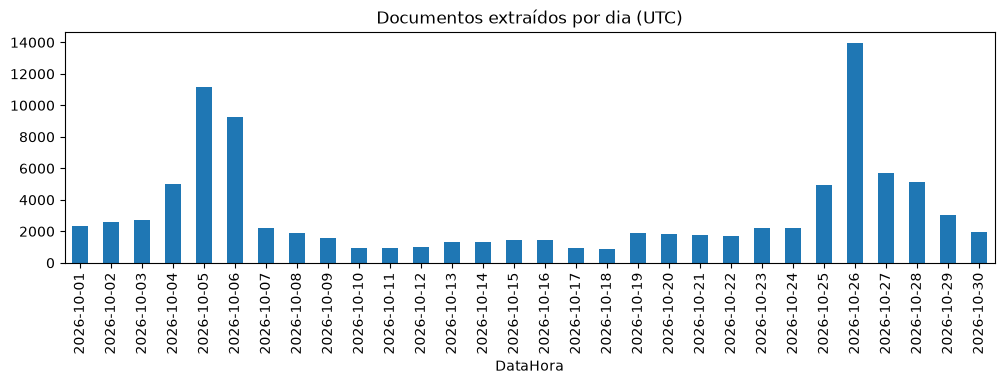

In [9]:
# Volume por dia (UTC): há buracos? o pico está onde esperado?
por_dia = df.groupby(pd.to_datetime(df["DataHora"]).dt.date).size()
por_dia.plot(kind="bar", figsize=(12, 3), title="Documentos extraídos por dia (UTC)");

In [10]:
# Top 30 veículos: os internacionais aparecem?
df["Veiculo"].value_counts().head(30)

Veiculo
globo.com                    19961
uol.com.br                    2738
brasil247.com                 2133
revistaforum.com.br           1570
estadao.com.br                1380
otempo.com.br                 1319
gazetadopovo.com.br           1256
riotimesonline.com            1160
correiobraziliense.com.br     1143
jornaldebrasilia.com.br       1103
abril.com.br                  1029
ig.com.br                     1013
r7.com                         931
terra.com.br                   897
em.com.br                      767
dgabc.com.br                   754
correiodopovo.com.br           738
opovo.com.br                   633
infomoney.com.br               626
correio24horas.com.br          596
tribunadonorte.com.br          564
ebc.com.br                     530
band.com.br                    518
diariodepernambuco.com.br      516
zazoom.it                      475
arede.info                     468
imirante.com                   453
tribunaonline.com.br           407
cartacapital

In [11]:
# Amostra
df[["DataHora", "Veiculo", "URL"]].sample(30, random_state=42)

,DataHora,Veiculo,URL
49379,2026-10-26 12:45:00+00:00,arn.ps,https://arn.ps/post/306838.html
56642,2026-10-06 05:30:00+00:00,globo.com,https://g1.globo.com/ba/bahia/eleicoes/2026/no...
56871,2026-10-06 19:45:00+00:00,globo.com,https://g1.globo.com/sp/sao-paulo/eleicoes/202...
6347,2026-10-10 04:00:00+00:00,clarin.com,https://www.clarin.com/opinion/reunion-cancill...
93764,2026-10-06 05:45:00+00:00,globo.com,https://g1.globo.com/pa/para/eleicoes/2026/not...
26259,2026-10-26 08:30:00+00:00,riotimesonline.com,https://www.riotimesonline.com/venezuela-rubio...
73674,2026-10-26 03:15:00+00:00,globo.com,https://g1.globo.com/es/espirito-santo/eleicoe...
30970,2026-10-06 16:15:00+00:00,gazetadopovo.com.br,https://www.gazetadopovo.com.br/eleicoes/2026/...
63047,2026-10-06 20:45:00+00:00,globo.com,https://g1.globo.com/to/tocantins/eleicoes/202...
29222,2026-10-25 23:30:00+00:00,globo.com,https://g1.globo.com/pb/paraiba/eleicoes/2026/...


In [12]:
import tldextract

df["Veiculo"] = df["Veiculo"].fillna("").str.lower().str.strip()
ext = df["Veiculo"].map(tldextract.extract)
df["tld"] = ext.map(lambda e: e.suffix)
df["domain"] = ext.map(lambda e: f"{e.domain}.{e.suffix}" if e.suffix else e.domain)

df["lang_origem"] = df["TranslationInfo"].str.extract(r"srclc:(\w+)")
df["is_por"] = df["lang_origem"].eq("por")

GENERICOS = {"com", "net", "org", "info", "tv", "co", "io", "news", "online"}
def grupo_prelim(tld):
    if tld == "": return "sem_dominio"
    if tld.endswith("br"): return "tld_br"
    if tld in GENERICOS: return "generico_ambiguo"
    return "tld_estrangeiro"
df["grupo_prelim"] = df["tld"].map(grupo_prelim)

# 1) Visão geral
print(df["grupo_prelim"].value_counts())
print(df["lang_origem"].value_counts(dropna=False).head(10))

# 2) Tabela por domínio
dom = (df.groupby("domain")
         .agg(n=("GKGRECORDID", "size"), pct_por=("is_por", "mean"), tld=("tld", "first"))
         .sort_values("n", ascending=False))

# 3) Candidatos a internacional: domínios com pouco português
cand = dom[dom["pct_por"] < 0.5]
print(f"\nDomínios candidatos a internacionais: {len(cand)} | documentos: {cand['n'].sum():,}")
display(cand.head(40))

# 4) Veículos internacionais conhecidos estão na base?
INTL = (r"reuters|bbc|theguardian|apnews|cnn|nytimes|washingtonpost|aljazeera|dw\.com|france24|"
        r"euronews|elpais|infobae|clarin|lemonde|bloomberg|efe\.com|ft\.com|wsj|skynews|"
        r"abcnews|nbcnews|cbsnews|rfi\.fr|swissinfo|xinhua|cgtn|independent\.co")
display(dom[dom.index.str.contains(INTL)])

# 5) Concentração: quanto os 3 maiores domínios pesam
print(f"\nTop 3 domínios = {dom['n'].head(3).sum()/dom['n'].sum()*100:.1f}% dos documentos")

grupo_prelim
generico_ambiguo    47818
tld_br              27735
tld_estrangeiro     19869
Name: count, dtype: int64
lang_origem
por    54295
spa    16470
NaN    11516
deu     2085
ita     1659
ell     1165
fra     1157
zho      948
rus      925
tur      544
Name: count, dtype: int64

Domínios candidatos a internacionais: 3704 | documentos: 39,440


,n,pct_por,tld
domain,,,
riotimesonline.com,1160,0.000000,com
zazoom.it,475,0.000000,it
perfil.com,379,0.000000,com
iheart.com,310,0.000000,com
dw.com,296,0.439189,com
lanacion.com.ar,264,0.000000,com.ar
euronews.com,254,0.192913,com
prensa-latina.cu,226,0.000000,cu
elpais.com.uy,214,0.000000,com.uy


,n,pct_por,tld
domain,,,
dw.com,296,0.439189,com
euronews.com,254,0.192913,com
elpais.com.uy,214,0.000000,com.uy
elpais.com,209,0.000000,com
clarin.com,201,0.000000,com
infobae.com,195,0.000000,com
bbc.com,109,0.623853,com
cnnchile.com,72,0.000000,com
theguardian.com,70,0.000000,com



Top 3 domínios = 26.0% dos documentos
